<a href="https://colab.research.google.com/github/tarun1208/BasicML/blob/main/News_Category_Classification_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q tensorflow datasets pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow Version:", tf.__version__)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

print("All libraries imported successfully!")

TensorFlow Version: 2.21.0
Pandas Version: 2.2.3
NumPy Version: 2.4.6
All libraries imported successfully!


In [ ]:
# Load AG News dataset

dataset = load_dataset("fancyzhx/ag_news")

print("Dataset downloaded successfully!")
print(dataset)

Dataset downloaded successfully!
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [63]:
from datasets import load_dataset

# Load AG News dataset
dataset = load_dataset("fancyzhx/ag_news")

# Display dataset information
print(dataset)

# Display first training sample
print("\nFirst Training Sample:")
print(dataset["train"][0])

# Display first testing sample
print("\nFirst Testing Sample:")
print(dataset["test"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

First Training Sample:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}

First Testing Sample:
{'text': "Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.", 'label': 2}


In [64]:
print("Training Dataset Information:")
print(train_df.info())

print("\nTesting Dataset Information:")
print(test_df.info())

print("\nFirst Five Training Records:")
print(train_df.head())

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   text        120000 non-null  object
 1   label       120000 non-null  int64 
 2   category    120000 non-null  object
 3   word_count  120000 non-null  int64 
 4   clean_text  120000 non-null  object
dtypes: int64(2), object(3)
memory usage: 4.6+ MB
None

Testing Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7600 entries, 0 to 7599
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   text        7600 non-null   object
 1   label       7600 non-null   int64 
 2   category    7600 non-null   object
 3   clean_text  7600 non-null   object
dtypes: int64(1), object(3)
memory usage: 237.6+ KB
None

First Five Training Records:
                                                text  l

In [ ]:
# Convert training dataset

train_df = dataset["train"].to_pandas()

# Convert testing dataset

test_df = dataset["test"].to_pandas()

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

Training Dataset Shape: (120000, 2)
Testing Dataset Shape: (7600, 2)


In [ ]:
# Category mapping

category_mapping = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

# Add category names

train_df["category"] = train_df["label"].map(category_mapping)

test_df["category"] = test_df["label"].map(category_mapping)

print(train_df.head())

                                                text  label  category
0  Wall St. Bears Claw Back Into the Black (Reute...      2  Business
1  Carlyle Looks Toward Commercial Aerospace (Reu...      2  Business
2  Oil and Economy Cloud Stocks' Outlook (Reuters...      2  Business
3  Iraq Halts Oil Exports from Main Southern Pipe...      2  Business
4  Oil prices soar to all-time record, posing new...      2  Business


In [ ]:
for i in range(5):

    print("News Article:", i + 1)

    print("Category:", train_df.iloc[i]["category"])

    print("News Content:", train_df.iloc[i]["text"])

    print("-" * 80)

News Article: 1
Category: Business
News Content: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
--------------------------------------------------------------------------------
News Article: 2
Category: Business
News Content: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.
--------------------------------------------------------------------------------
News Article: 3
Category: Business
News Content: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.
----------------------------------------------

In [ ]:
print("Training Dataset Information:")

print(train_df.info())

print("\nTesting Dataset Information:")

print(test_df.info())

print("\nMissing Values:")

print(train_df.isnull().sum())

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   text      120000 non-null  object
 1   label     120000 non-null  int64 
 2   category  120000 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.7+ MB
None

Testing Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7600 entries, 0 to 7599
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      7600 non-null   object
 1   label     7600 non-null   int64 
 2   category  7600 non-null   object
dtypes: int64(1), object(2)
memory usage: 178.3+ KB
None

Missing Values:
text        0
label       0
category    0
dtype: int64


In [ ]:
print("Available Categories:")

print(train_df["category"].unique())

Available Categories:
['Business' 'Sci/Tech' 'Sports' 'World']


In [ ]:
print("Training Dataset Category Counts:")

print(train_df["category"].value_counts())

print("\nTesting Dataset Category Counts:")

print(test_df["category"].value_counts())

Training Dataset Category Counts:
category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64

Testing Dataset Category Counts:
category
Business    1900
Sci/Tech    1900
Sports      1900
World       1900
Name: count, dtype: int64


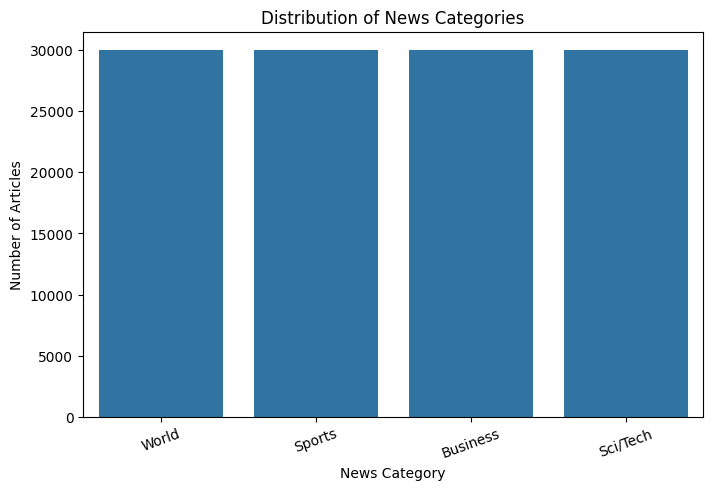

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="category",
    order=["World", "Sports", "Business", "Sci/Tech"]
)

plt.title("Distribution of News Categories")

plt.xlabel("News Category")

plt.ylabel("Number of Articles")

plt.xticks(rotation=20)

plt.show()

In [ ]:
train_df["word_count"] = train_df["text"].apply(
    lambda x: len(x.split())
)

print(train_df[["text", "word_count", "category"]].head())

                                                text  word_count  category
0  Wall St. Bears Claw Back Into the Black (Reute...          21  Business
1  Carlyle Looks Toward Commercial Aerospace (Reu...          36  Business
2  Oil and Economy Cloud Stocks' Outlook (Reuters...          36  Business
3  Iraq Halts Oil Exports from Main Southern Pipe...          36  Business
4  Oil prices soar to all-time record, posing new...          37  Business


In [ ]:
print("Article Length Statistics:")

print(train_df["word_count"].describe())

Article Length Statistics:
count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: word_count, dtype: float64


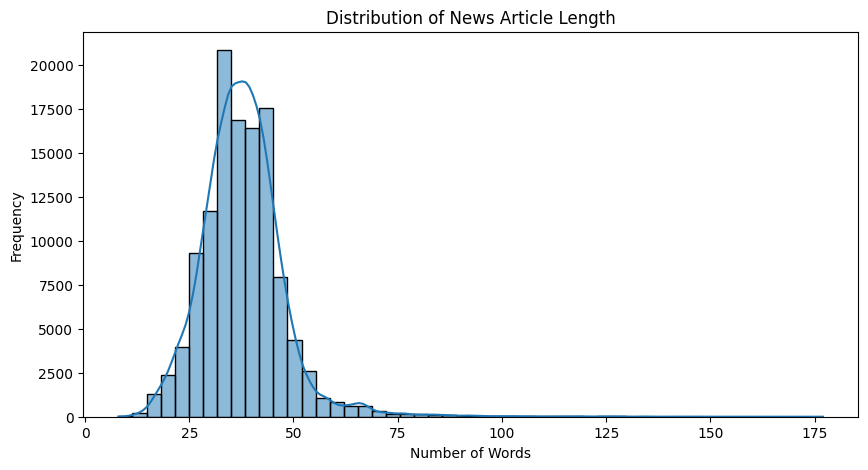

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["word_count"],
    bins=50,
    kde=True
)

plt.title("Distribution of News Article Length")

plt.xlabel("Number of Words")

plt.ylabel("Frequency")

plt.show()

In [ ]:
print("Missing Values:")

print(train_df.isnull().sum())

print("\nTesting Missing Values:")

print(test_df.isnull().sum())

Missing Values:
text          0
label         0
category      0
word_count    0
dtype: int64

Testing Missing Values:
text        0
label       0
category    0
dtype: int64


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import re

In [ ]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Keep alphabets and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
train_df["clean_text"] = train_df["text"].apply(clean_text)

test_df["clean_text"] = test_df["text"].apply(clean_text)

In [ ]:
print("Original Text:")

print(train_df["text"].iloc[0])

print("\nCleaned Text:")

print(train_df["clean_text"].iloc[0])

Original Text:
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

Cleaned Text:
wall st bears claw back into the black reuters reuters short sellers wall street s dwindling band of ultra cynics are seeing green again


In [ ]:
MAX_WORDS = 20000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit tokenizer only on training data
tokenizer.fit_on_texts(train_df["clean_text"])

print("Total Words Found:", len(tokenizer.word_index))

Total Words Found: 61819


In [ ]:
X_train_sequences = tokenizer.texts_to_sequences(
    train_df["clean_text"]
)

X_test_sequences = tokenizer.texts_to_sequences(
    test_df["clean_text"]
)

In [ ]:
print("Original Text:")

print(train_df["clean_text"].iloc[0])

print("\nNumerical Sequence:")

print(X_train_sequences[0])

Original Text:
wall st bears claw back into the black reuters reuters short sellers wall street s dwindling band of ultra cynics are seeing green again

Numerical Sequence:
[434, 359, 1605, 13971, 106, 62, 2, 822, 21, 21, 729, 7896, 434, 376, 8, 9873, 2821, 5, 5610, 1, 40, 3933, 766, 329]


In [ ]:
MAX_LENGTH = 100

X_train = pad_sequences(
    X_train_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

In [ ]:
print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

Training Data Shape: (120000, 100)
Testing Data Shape: (7600, 100)


In [ ]:
print("First Training Article:")

print(X_train[0])

print("\nFirst Testing Article:")

print(X_test[0])

First Training Article:
[  434   359  1605 13971   106    62     2   822    21    21   729  7896
   434   376     8  9873  2821     5  5610     1    40  3933   766   329
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0]

First Testing Article:
[ 861   10   78   95 1463   28  170 1763 4000  411   14 6412    1  238
   65   40 4400   28  170   12 7479 2443  332  193 9050    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0   

In [ ]:
y_train = train_df["label"].values

y_test = test_df["label"].values

print("Training Labels Shape:", y_train.shape)

print("Testing Labels Shape:", y_test.shape)

Training Labels Shape: (120000,)
Testing Labels Shape: (7600,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training Data:", X_train_final.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Labels:", y_train_final.shape)
print("Validation Labels:", y_val.shape)
print("Testing Labels:", y_test.shape)

Training Data: (96000, 100)
Validation Data: (24000, 100)
Testing Data: (7600, 100)

Training Labels: (96000,)
Validation Labels: (24000,)
Testing Labels: (7600,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

# Create ANN model

model = Sequential([

    # Input layer
    Input(shape=(MAX_LENGTH,)),

    # Embedding layer
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),

    # Convert sequence into fixed-size vector
    GlobalAveragePooling1D(),

    # First hidden layer
    Dense(128, activation="relu"),

    # Dropout layer
    Dropout(0.3),

    # Second hidden layer
    Dense(64, activation="relu"),

    # Output layer
    Dense(4, activation="softmax")
])

print("ANN Model Created Successfully!")

ANN Model Created Successfully!


In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,296,836 (4.95 MB)

 Trainable params: 1,296,836 (4.95 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Training parameters

EPOCHS = 10
BATCH_SIZE = 128

# Train ANN model

history = model.fit(
    X_train_final,
    y_train_final,

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    validation_data=(X_val, y_val),

    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.8757 - loss: 0.3780 - val_accuracy: 0.9221 - val_loss: 0.2366
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9357 - loss: 0.1949 - val_accuracy: 0.9210 - val_loss: 0.2371
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - accuracy: 0.9478 - loss: 0.1512 - val_accuracy: 0.9156 - val_loss: 0.2615
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9565 - loss: 0.1209 - val_accuracy: 0.9125 - val_loss: 0.3032
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9636 - loss: 0.0969 - val_accuracy: 0.9089 - val_loss: 0.3553
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9690 - loss: 0.0801 - val_accuracy: 0.9075 - val_loss: 0.4123
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.9740 - loss: 0.0654 - val_accuracy: 0.9047 - val_loss: 0.4781
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.9784 - loss: 0.0536 - 

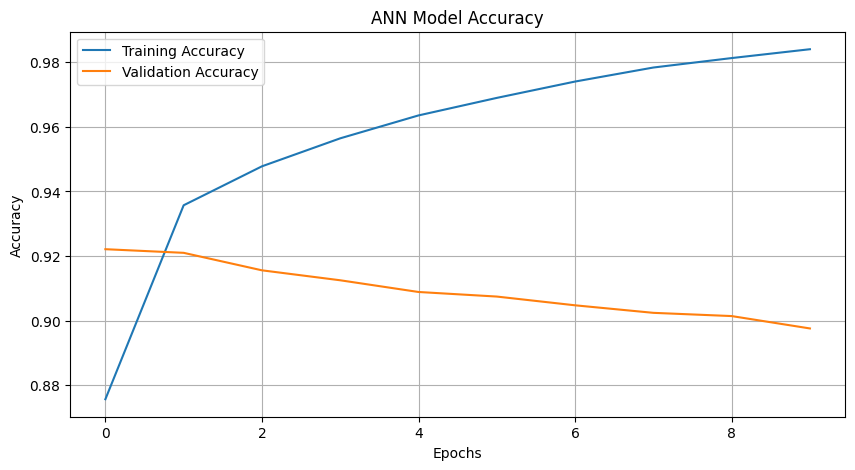

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ANN Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

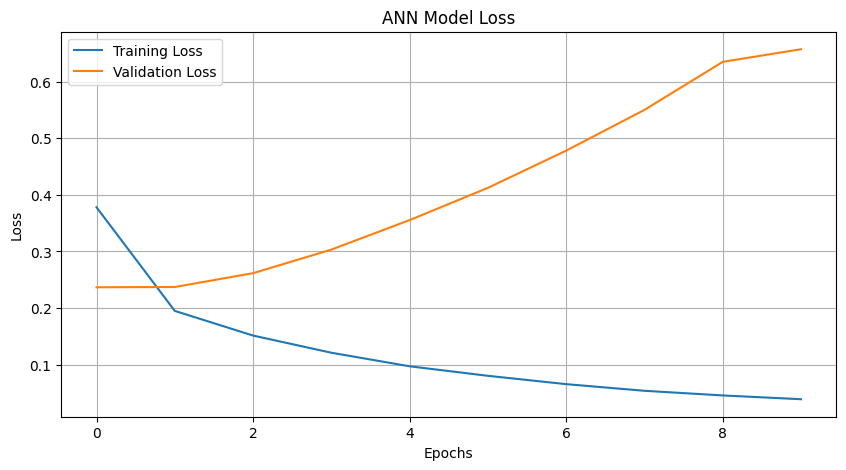

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ANN Model Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

model = Sequential([

    Input(shape=(MAX_LENGTH,)),

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),

    GlobalAveragePooling1D(),

    Dropout(0.2),

    Dense(128, activation="relu"),

    Dropout(0.4),

    Dense(64, activation="relu"),

    Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved ANN Model Created!")

Improved ANN Model Created!


In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=0.00001,
    verbose=1
)

In [ ]:
EPOCHS = 15
BATCH_SIZE = 128

history = model.fit(
    X_train_final,
    y_train_final,

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    validation_data=(X_val, y_val),

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.8734 - loss: 0.3891 - val_accuracy: 0.9213 - val_loss: 0.2406 - learning_rate: 0.0010
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9357 - loss: 0.1991
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9338 - loss: 0.2037 - val_accuracy: 0.9203 - val_loss: 0.2407 - learning_rate: 0.0010
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9527 - loss: 0.1460
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9516 - loss: 0.1473 - val_accuracy: 0.9196 - val_loss: 0.2539 - learning_rate: 5.0000e-04
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


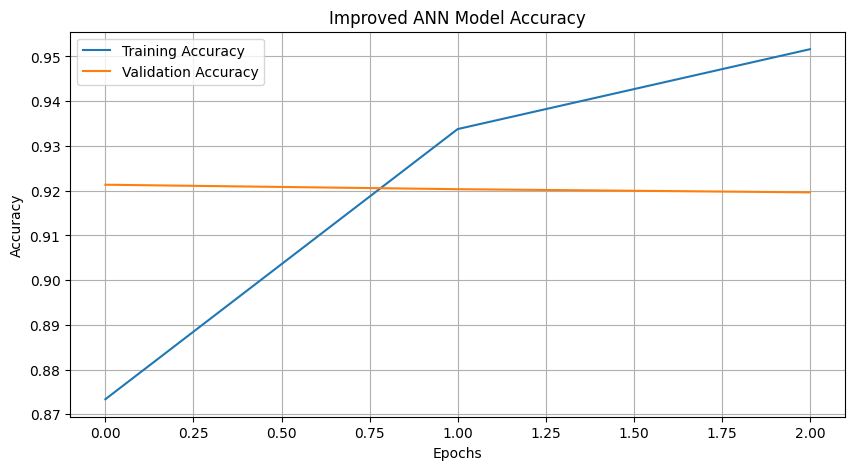

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"],
         label="Training Accuracy")

plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("Improved ANN Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

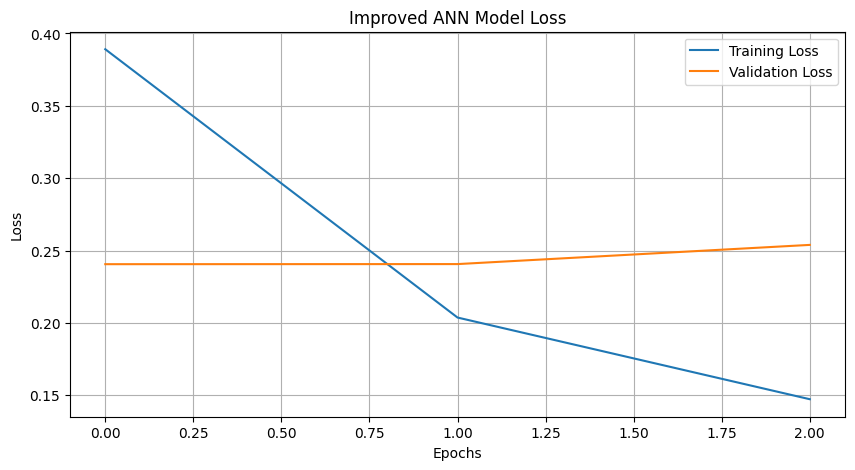

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"],
         label="Training Loss")

plt.plot(history.history["val_loss"],
         label="Validation Loss")

plt.title("Improved ANN Model Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
baseline_history = history.history.copy()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nFinal Model Evaluation")

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9151 - loss: 0.2551

Final Model Evaluation
Test Loss: 0.2550954520702362
Test Accuracy: 91.51315689086914 %


In [ ]:
y_pred_prob = model.predict(X_test)

print("Prediction Shape:", y_pred_prob.shape)

238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Prediction Shape: (7600, 4)


In [ ]:
y_pred = np.argmax(y_pred_prob, axis=1)

print("Predicted Labels:", y_pred[:20])

print("Actual Labels:", y_test[:20])

Predicted Labels: [2 3 3 3 3 3 3 3 3 2 3 3 3 3 3 3 3 3 3 3]
Actual Labels: [2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Model Performance")

print("Accuracy:", accuracy * 100, "%")

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

Model Performance
Accuracy: 91.51315789473684 %
Precision: 0.9154728035972696
Recall: 0.9151315789473684
F1 Score: 0.915097373692195


In [ ]:
target_names = [
    "World",
    "Sports",
    "Business",
    "Sci/Tech"
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=target_names
    )
)

              precision    recall  f1-score   support

       World       0.94      0.90      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.87      0.90      0.88      1900
    Sci/Tech       0.90      0.88      0.89      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



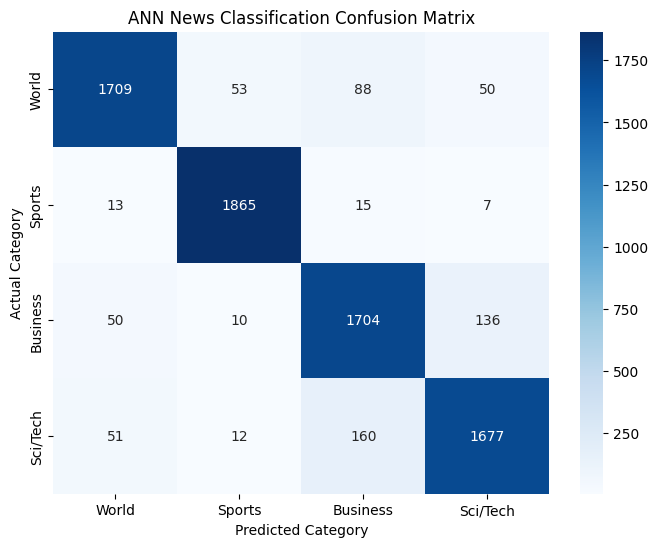

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title("ANN News Classification Confusion Matrix")

plt.xlabel("Predicted Category")

plt.ylabel("Actual Category")

plt.show()

In [ ]:
results_df = pd.DataFrame({

    "Actual Category": [
        category_mapping[i] for i in y_test[:15]
    ],

    "Predicted Category": [
        category_mapping[i] for i in y_pred[:15]
    ]

})

print(results_df)

   Actual Category Predicted Category
0         Business           Business
1         Sci/Tech           Sci/Tech
2         Sci/Tech           Sci/Tech
3         Sci/Tech           Sci/Tech
4         Sci/Tech           Sci/Tech
5         Sci/Tech           Sci/Tech
6         Sci/Tech           Sci/Tech
7         Sci/Tech           Sci/Tech
8         Sci/Tech           Sci/Tech
9         Sci/Tech           Business
10        Sci/Tech           Sci/Tech
11        Sci/Tech           Sci/Tech
12        Sci/Tech           Sci/Tech
13        Sci/Tech           Sci/Tech
14        Sci/Tech           Sci/Tech


In [ ]:
def predict_news(news):

    # Step 1: Clean the input text
    cleaned_news = clean_text(news)

    # Step 2: Convert text into numerical sequence
    sequence = tokenizer.texts_to_sequences([cleaned_news])

    # Step 3: Apply padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    # Step 4: Predict category probabilities
    prediction = model.predict(
        padded_sequence,
        verbose=0
    )

    # Step 5: Get predicted category
    predicted_label = np.argmax(prediction, axis=1)[0]

    predicted_category = category_mapping[predicted_label]

    # Step 6: Get confidence
    confidence = np.max(prediction) * 100

    print("\nNews Classification Result")
    print("-" * 40)

    print("News:", news)

    print("Predicted Category:", predicted_category)

    print("Confidence:", round(confidence, 2), "%")

    print("\nCategory Probabilities:")

    for i, category in category_mapping.items():

        print(
            category,
            ":",
            round(prediction[0][i] * 100, 2),
            "%"
        )

    return predicted_category

# Test individual news articles

In [ ]:
news1 = """
India defeated Australia in the cricket match
after scoring 250 runs and winning the tournament.
"""

predict_news(news1)


News Classification Result
----------------------------------------
News: 
India defeated Australia in the cricket match
after scoring 250 runs and winning the tournament.

Predicted Category: Sports
Confidence: 99.88 %

Category Probabilities:
World : 0.12 %
Sports : 99.88 %
Business : 0.0 %
Sci/Tech : 0.0 %


'Sports'

In [ ]:
news2 = """
The stock market witnessed a major increase
as several companies reported higher profits.
"""

predict_news(news2)


News Classification Result
----------------------------------------
News: 
The stock market witnessed a major increase
as several companies reported higher profits.

Predicted Category: Business
Confidence: 99.5 %

Category Probabilities:
World : 0.3 %
Sports : 0.0 %
Business : 99.5 %
Sci/Tech : 0.2 %


'Business'

In [ ]:
news3 = """
Leaders from several countries attended an
international summit to discuss global security.
"""

predict_news(news3)


News Classification Result
----------------------------------------
News: 
Leaders from several countries attended an
international summit to discuss global security.

Predicted Category: World
Confidence: 99.17 %

Category Probabilities:
World : 99.17 %
Sports : 0.0 %
Business : 0.18 %
Sci/Tech : 0.65 %


'World'

In [ ]:
news4 = """
Scientists developed a new artificial intelligence
technology that improves computer performance.
"""

predict_news(news4)


News Classification Result
----------------------------------------
News: 
Scientists developed a new artificial intelligence
technology that improves computer performance.

Predicted Category: Sci/Tech
Confidence: 99.64 %

Category Probabilities:
World : 0.14 %
Sports : 0.0 %
Business : 0.21 %
Sci/Tech : 99.64 %


'Sci/Tech'

In [ ]:
my_news = """
India Under-19 defeated Afghanistan by 8 wickets
in the semi-final after chasing down the target
and reaching the Asia Cup final against Pakistan.
"""

predict_news(my_news)


News Classification Result
----------------------------------------
News: 
India Under-19 defeated Afghanistan by 8 wickets
in the semi-final after chasing down the target
and reaching the Asia Cup final against Pakistan.

Predicted Category: Sports
Confidence: 77.89 %

Category Probabilities:
World : 21.38 %
Sports : 77.89 %
Business : 0.56 %
Sci/Tech : 0.17 %


'Sports'

In [ ]:
model.save("news_classification_ann.keras")

print("ANN Model Saved Successfully!")

ANN Model Saved Successfully!


In [ ]:
import pickle

with open("news_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer Saved Successfully!")

Tokenizer Saved Successfully!


In [ ]:
with open("category_mapping.pkl", "wb") as file:
    pickle.dump(category_mapping, file)

print("Category Mapping Saved Successfully!")

Category Mapping Saved Successfully!


In [ ]:
import os

print(os.listdir())

['.config', 'news_classification_ann.keras', 'category_mapping.pkl', 'news_tokenizer.pkl', 'sample_data']


In [ ]:
from google.colab import files

files.download("news_classification_ann.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("news_tokenizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("category_mapping.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>